# Tahap 1 — Eksplorasi Metadata COUGHVID v3

Notebook ini adalah bagian **Akuisisi** pada *pipeline* pengenalan pola suara (slide 10):
memahami data mentah sebelum *preprocessing*. Data: COUGHVID v3 (Orlandic dkk., 2021) —
rekaman batuk *crowdsourced* dari mikrofon *smartphone*/web.

Isi: struktur kolom & *missing value*, distribusi label (`status`, `status_SSL`), demografi,
`cough_detected`, populasi Eksperimen A, label ahli (`diagnosis_1..4`), dan contoh sifat sinyal
digital (durasi & *sampling rate* asli).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')

import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.config import load_config, set_seed
from src import data_utils as du
from src.plots import setup_style, save_fig, save_table, bar_counts

cfg = load_config(); set_seed(cfg.seed); setup_style()
THR = cfg.data.cough_detected_threshold
pd.set_option('display.max_rows', 60, 'display.width', 140)

## 1. Memuat metadata & pemetaan uuid → file audio

In [2]:
df = du.load_metadata()
print('Jumlah baris metadata :', len(df))
print('uuid unik             :', df['uuid'].nunique())
print('Punya file audio      :', df['audio_path'].notna().sum())
print('Tanpa file audio      :', df['audio_path'].isna().sum())
print('File audio tanpa baris metadata:', len(set(du.uuid_to_audio_path()) - set(df['uuid'])))
df['audio_ext'].value_counts(dropna=False).rename('jumlah').to_frame()

Jumlah baris metadata : 34434
uuid unik             : 34434
Punya file audio      : 34434
Tanpa file audio      : 0


File audio tanpa baris metadata: 0


,jumlah
audio_ext,
.webm,29348
.wav,3309
.ogg,1777


## 2. Daftar kolom, tipe data, dan persentase *missing*

In [3]:
info = pd.DataFrame({'dtype': df.dtypes.astype(str),
                     'n_non_null': df.notna().sum(),
                     'missing_%': (df.isna().mean() * 100).round(2),
                     'n_unique': df.nunique()})
save_table(info, '01_kolom_missing')
info

,dtype,n_non_null,missing_%,n_unique
uuid,object,34434,0.00,34434
datetime,"datetime64[ns, UTC]",34434,0.00,34434
cough_detected,float64,34434,0.00,7958
latitude,float64,19431,43.57,834
longitude,float64,19431,43.57,1551
age,float64,19396,43.67,99
gender,object,20664,39.99,3
respiratory_condition,boolean,20664,39.99,2
fever_muscle_pain,boolean,20664,39.99,2
status,object,20664,39.99,3


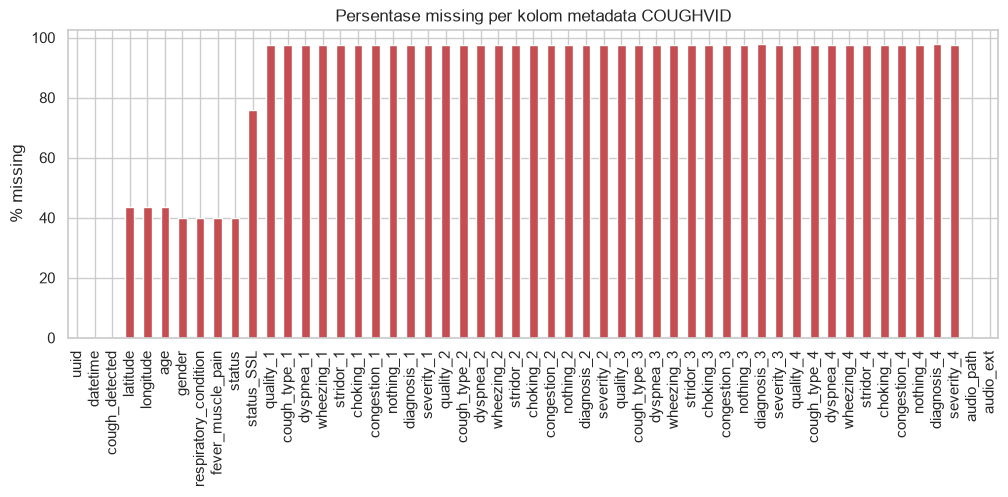

In [4]:
fig, ax = plt.subplots(figsize=(12, 4))
info['missing_%'].plot.bar(ax=ax, color='#C44E52')
ax.set_ylabel('% missing'); ax.set_title('Persentase missing per kolom metadata COUGHVID')
save_fig(fig, '01_missing_per_kolom'); plt.show()

## 3. Distribusi label & demografi

`status` adalah label *self-reported* (diisi pengguna sendiri); `status_SSL` adalah label hasil
*semi-supervised learning* yang ditambahkan pada v3. Keduanya tidak diverifikasi PCR (lihat R4).

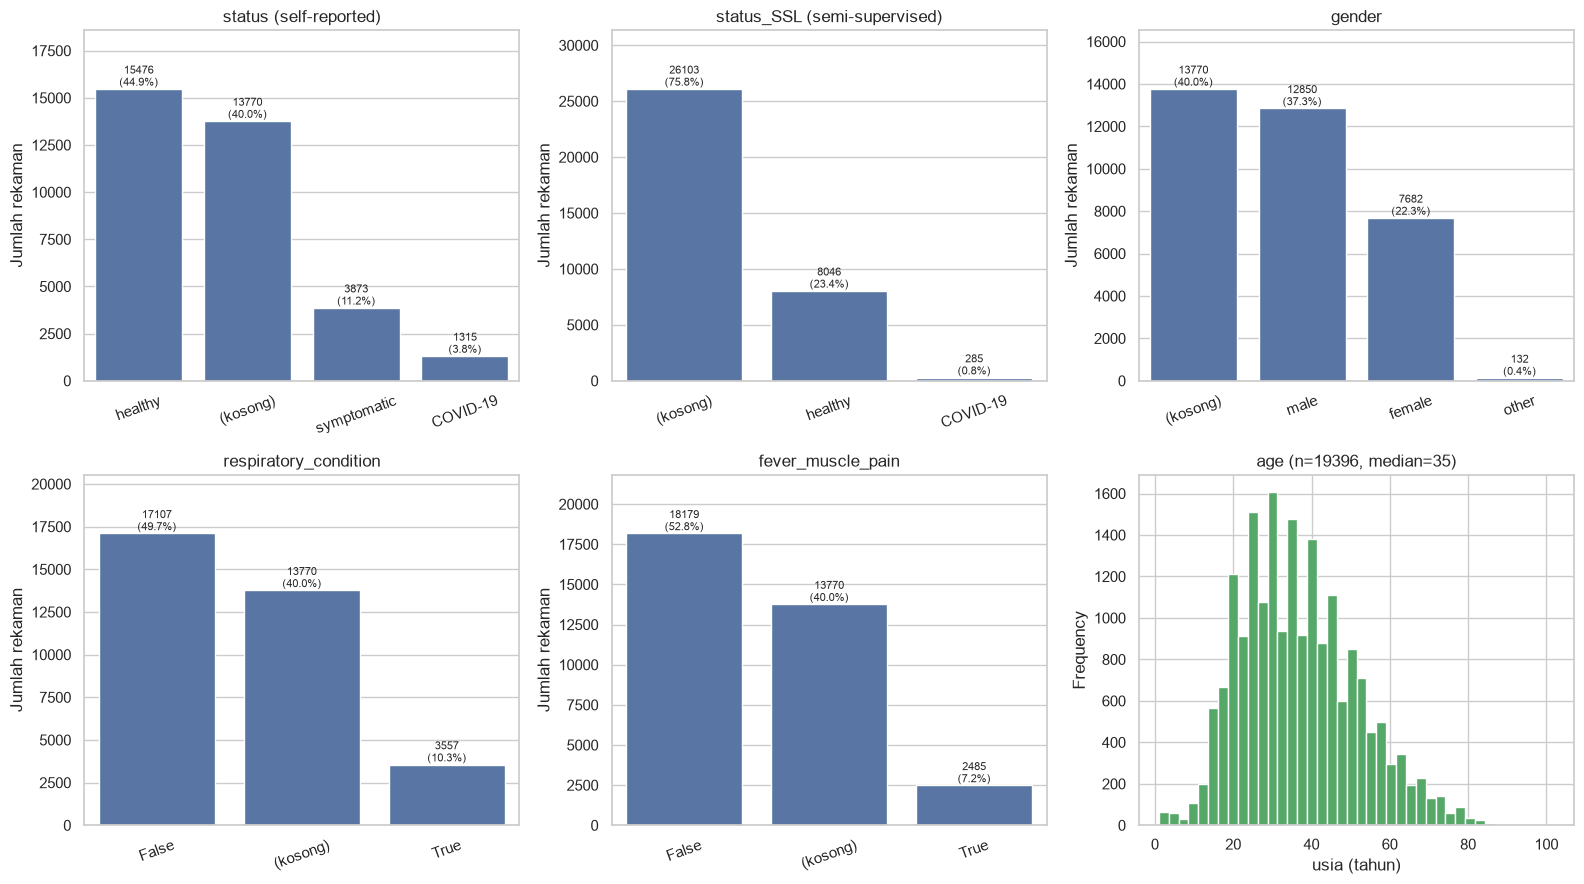

count    19396.0
mean        36.8
std         14.8
min          1.0
25%         25.0
50%         35.0
75%         46.0
max        102.0


In [5]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
bar_counts(df['status'], 'status (self-reported)', axes[0, 0])
bar_counts(df['status_SSL'], 'status_SSL (semi-supervised)', axes[0, 1])
bar_counts(df['gender'], 'gender', axes[0, 2])
bar_counts(df['respiratory_condition'], 'respiratory_condition', axes[1, 0])
bar_counts(df['fever_muscle_pain'], 'fever_muscle_pain', axes[1, 1])
ax = axes[1, 2]
df['age'].dropna().plot.hist(bins=40, ax=ax, color='#55A868', edgecolor='white')
ax.set_title(f"age (n={df['age'].notna().sum()}, median={df['age'].median():.0f})"); ax.set_xlabel('usia (tahun)')
fig.tight_layout(); save_fig(fig, '01_distribusi_label_demografi'); plt.show()

dist = pd.concat({c: df[c].astype('object').fillna('(kosong)').value_counts()
                  for c in ['status', 'status_SSL', 'gender', 'respiratory_condition', 'fever_muscle_pain']})
dist = dist.rename('jumlah').to_frame(); save_table(dist, '01_distribusi_kategori')
print(df['age'].describe().round(1).to_string())

In [6]:
ct_ssl = pd.crosstab(df['status'].fillna('(kosong)'), df['status_SSL'].fillna('(kosong)'), margins=True)
save_table(ct_ssl, '01_crosstab_status_vs_statusSSL'); ct_ssl

status_SSL,(kosong),COVID-19,healthy,All
status,,,,
(kosong),12723,18,1029,13770
COVID-19,973,201,141,1315
healthy,9115,34,6327,15476
symptomatic,3292,32,549,3873
All,26103,285,8046,34434


## 4. `cough_detected` dan populasi Eksperimen A

`cough_detected` adalah probabilitas (dari *classifier* batuk milik penulis dataset) bahwa
rekaman benar-benar berisi batuk. Penulis merekomendasikan ambang **≥ 0.8**.

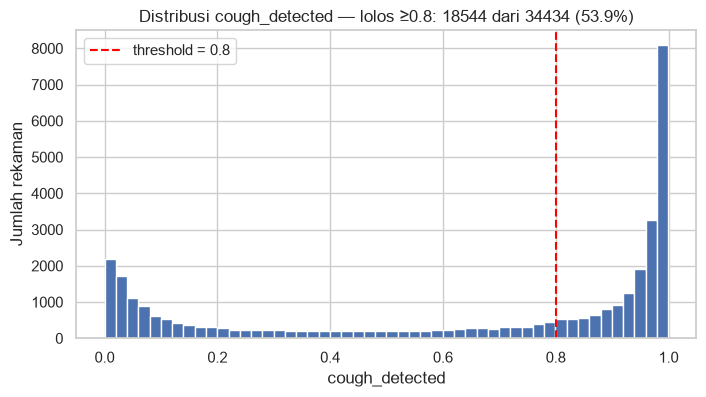

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df['cough_detected'].dropna(), bins=50, color='#4C72B0', edgecolor='white')
ax.axvline(THR, color='red', ls='--', label=f'threshold = {THR}')
n_pass = (df['cough_detected'] >= THR).sum()
ax.set_title(f'Distribusi cough_detected — lolos ≥{THR}: {n_pass} dari {len(df)} ({n_pass/len(df):.1%})')
ax.set_xlabel('cough_detected'); ax.set_ylabel('Jumlah rekaman'); ax.legend()
save_fig(fig, '01_hist_cough_detected'); plt.show()

In [8]:
df['lolos_thr'] = np.where(df['cough_detected'] >= THR, f'>= {THR}', f'< {THR}')
ct = pd.crosstab(df['status'].fillna('(kosong)'), df['lolos_thr'], margins=True)
save_table(ct, '01_crosstab_status_x_cough_detected')
ct

lolos_thr,< 0.8,>= 0.8,All
status,,,
(kosong),8761,5009,13770
COVID-19,595,720,1315
healthy,5344,10132,15476
symptomatic,1190,2683,3873
All,15890,18544,34434


In [9]:
popA = df[(df['cough_detected'] >= THR) & df['status'].isin(['COVID-19', 'healthy']) & df['audio_path'].notna()]
popA_counts = popA['status'].value_counts().rename('jumlah').to_frame()
popA_counts['proporsi'] = (popA_counts['jumlah'] / popA_counts['jumlah'].sum()).round(4)
save_table(popA_counts, '01_populasi_eksperimen_A')
print(f'Populasi Eksperimen A (COVID-19 vs healthy, cough_detected>={THR}, file ada): {len(popA)}')
print(f"Rasio healthy : COVID-19 = {popA_counts.loc['healthy','jumlah']/popA_counts.loc['COVID-19','jumlah']:.1f} : 1")
popA_counts

Populasi Eksperimen A (COVID-19 vs healthy, cough_detected>=0.8, file ada): 10852
Rasio healthy : COVID-19 = 14.1 : 1


,jumlah,proporsi
status,,
healthy,10132,0.9337
COVID-19,720,0.0663


## 5. Label ahli (pulmonolog) — dasar Eksperimen B

Sebagian rekaman dianotasi oleh hingga 4 ahli (`diagnosis_1..4`, `quality_*`, dst.).

In [10]:
diag_cols = du.expert_label_columns('diagnosis')
lab = du.expert_labeled_mask(df)
n_exp = df[diag_cols].notna().sum(axis=1)
print('Rekaman berlabel ahli (>=1 diagnosis):', lab.sum())
print('Distribusi jumlah ahli per rekaman:'); print(n_exp[lab].value_counts().sort_index().to_string())
print('Anotasi per ahli:', df[diag_cols].notna().sum().to_dict())

long = du.expert_long(df)
diag_dist = long['diagnosis'].value_counts().rename('jumlah_anotasi').to_frame()
save_table(diag_dist, '01_distribusi_diagnosis_ahli')
diag_dist

Rekaman berlabel ahli (>=1 diagnosis): 2841
Distribusi jumlah ahli per rekaman:
1    2711
2       3
3       1
4     126
Anotasi per ahli: {'diagnosis_1': 820, 'diagnosis_2': 820, 'diagnosis_3': 793, 'diagnosis_4': 791}


,jumlah_anotasi
diagnosis,
upper_infection,883
healthy_cough,746
lower_infection,732
COVID-19,649
obstructive_disease,214


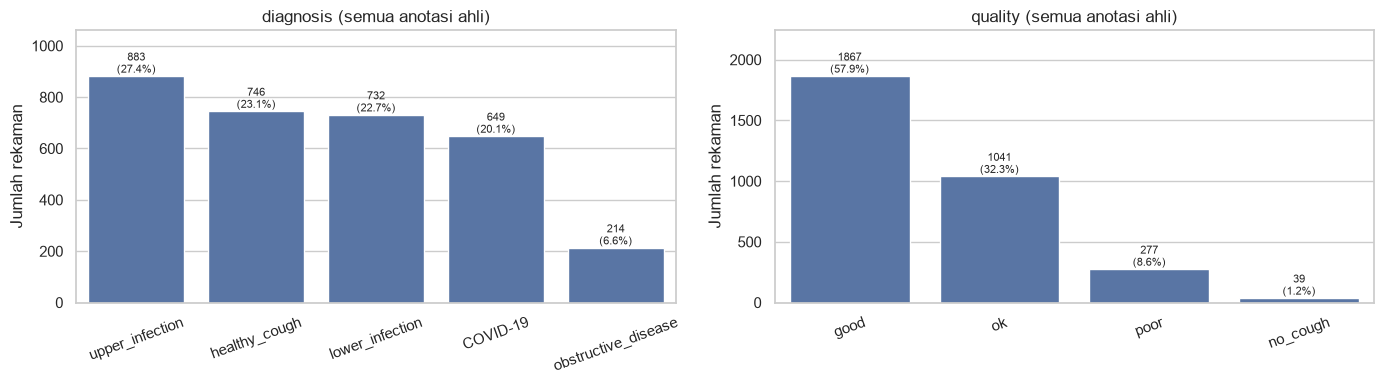

Self-reported status vs diagnosis ahli (per anotasi):


diagnosis,COVID-19,healthy_cough,lower_infection,obstructive_disease,upper_infection,All
status,,,,,,
(kosong),80,115,84,18,95,392
COVID-19,161,212,165,56,216,810
healthy,172,217,172,52,258,871
symptomatic,236,202,311,88,314,1151
All,649,746,732,214,883,3224


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
bar_counts(long['diagnosis'], 'diagnosis (semua anotasi ahli)', axes[0])
bar_counts(long['quality'], 'quality (semua anotasi ahli)', axes[1])
fig.tight_layout(); save_fig(fig, '01_label_ahli'); plt.show()

ct_exp = pd.crosstab(long.merge(df[['uuid', 'status']], on='uuid')['status'].fillna('(kosong)'),
                     long['diagnosis'], margins=True)
save_table(ct_exp, '01_crosstab_status_x_diagnosis_ahli')
print('Self-reported status vs diagnosis ahli (per anotasi):'); ct_exp

## 6. Contoh sinyal digital: durasi & *sampling rate* asli

Audio asli adalah sinyal **digital** hasil *sampling* (laju sampel = *sampling rate*) dan
*quantization* oleh perangkat perekam. Codec terkompresi (Opus dalam .webm, Vorbis dalam .ogg)
didekode dengan **ffmpeg**. Diambil 5 sampel acak per kelas `status` (seed 42).

In [12]:
samples = (df[df['audio_path'].notna() & df['status'].notna()]
           .groupby('status', group_keys=False).apply(lambda g: g.sample(5, random_state=cfg.seed)))
info_audio = pd.DataFrame([{**{'uuid': r.uuid, 'status': r.status, 'ext': r.audio_ext,
                               'cough_detected': r.cough_detected}, **du.probe_audio(r.audio_path)}
                           for r in samples.itertuples()])
save_table(info_audio, '01_sampel_audio_info', index=False)
info_audio.round(3)

,uuid,status,ext,cough_detected,codec,sr_native,channels,n_samples,duration_s
0,260ef2a5-b9d2-41e7-afc7-bed26e7af5b9,COVID-19,.webm,0.920,opus,48000,1,83520,1.740
1,e3244803-32bb-4706-b14a-0bfb384b96de,COVID-19,.webm,0.016,opus,48000,1,466560,9.720
2,abe342aa-1acc-40d4-8b39-b2a81ed69512,COVID-19,.webm,0.751,opus,48000,1,469440,9.780
3,37b27ce5-a134-431d-ae71-8c3c6fe273af,COVID-19,.webm,0.791,opus,48000,1,466560,9.720
4,23ad16a0-1a5b-4dfc-b326-f916f31fafe3,COVID-19,.webm,0.993,opus,48000,1,469440,9.780
5,1737fd6e-aa59-485f-a836-138c0320078a,healthy,.webm,0.909,opus,48000,1,285120,5.940
6,e6d10c01-1393-48f1-9ced-fa1a5498112c,healthy,.webm,0.890,opus,48000,1,132480,2.760
7,0e65945d-1e50-4172-bf6f-6bf85a81a315,healthy,.webm,0.850,opus,48000,1,184320,3.840
8,d46d543a-cae1-43fb-9ee9-4629f7ec1a51,healthy,.ogg,0.537,opus,48000,1,457984,9.541
9,45d5199f-9af4-4310-b394-ca46da59f144,healthy,.webm,0.043,opus,48000,1,472320,9.840


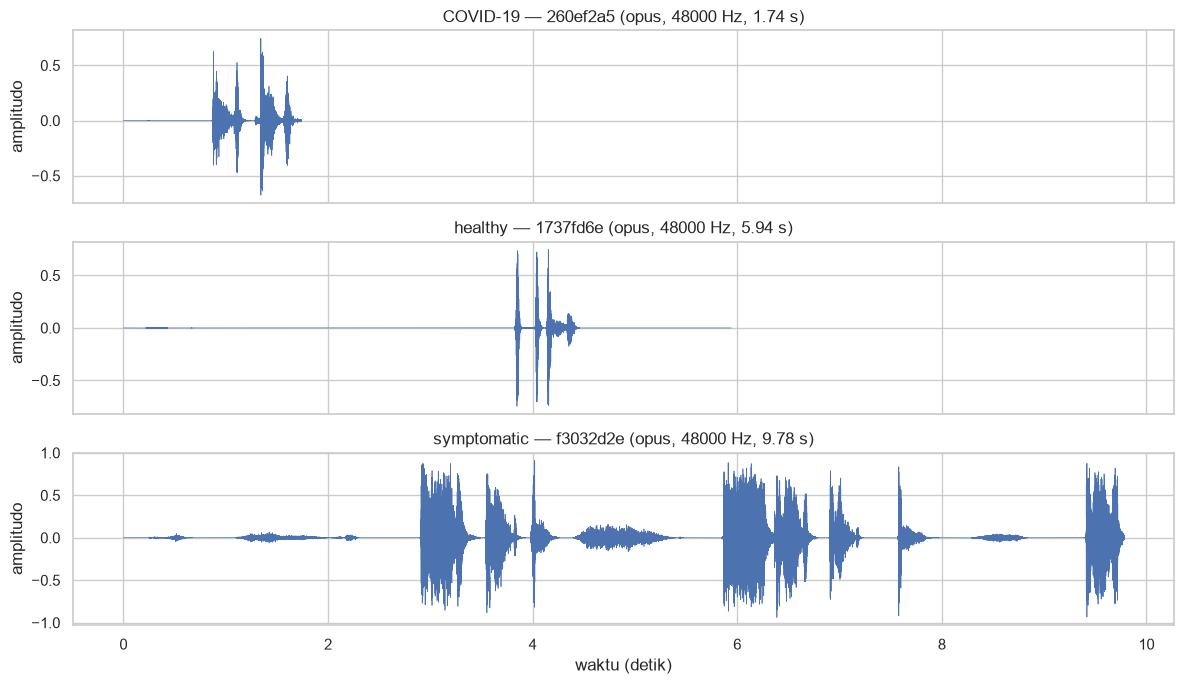

In [13]:
fig, axes = plt.subplots(len(samples['status'].unique()), 1, figsize=(12, 7), sharex=True)
for ax, (st, g) in zip(axes, samples.groupby('status')):
    r = g.iloc[0]; info = du.probe_audio(r.audio_path)
    y = du.load_audio_ffmpeg(r.audio_path, sr=None); t = np.arange(len(y)) / info['sr_native']
    ax.plot(t, y, lw=0.5); ax.set_title(f"{st} — {r.uuid[:8]} ({info['codec']}, {info['sr_native']} Hz, {info['duration_s']:.2f} s)")
    ax.set_ylabel('amplitudo')
axes[-1].set_xlabel('waktu (detik)'); fig.tight_layout(); save_fig(fig, '01_contoh_waveform'); plt.show()

## 7. Ringkasan
Angka kunci ditulis ke `reports/tables/01_ringkasan_angka.csv` dan dirangkum di `PROGRESS.md`.

In [14]:
summary = pd.Series({
    'total_baris_metadata': len(df),
    'total_file_audio': df['audio_path'].notna().sum(),
    'lolos_cough_detected': int((df['cough_detected'] >= THR).sum()),
    'popA_covid': int((popA['status'] == 'COVID-19').sum()),
    'popA_healthy': int((popA['status'] == 'healthy').sum()),
    'symptomatic_lolos_thr': int(((df['status'] == 'symptomatic') & (df['cough_detected'] >= THR)).sum()),
    'berlabel_ahli': int(lab.sum()),
    'nilai_unik_diagnosis': '; '.join(sorted(long['diagnosis'].dropna().unique())),
}, name='nilai')
save_table(summary.to_frame(), '01_ringkasan_angka'); summary

total_baris_metadata                                                 34434
total_file_audio                                                     34434
lolos_cough_detected                                                 18544
popA_covid                                                             720
popA_healthy                                                         10132
symptomatic_lolos_thr                                                 2683
berlabel_ahli                                                         2841
nilai_unik_diagnosis     COVID-19; healthy_cough; lower_infection; obst...
Name: nilai, dtype: object